> **Bản PyTorch** của `examples/1. MLP/MNIST_MLP.ipynb` (Keras). Người chuyển: TV2 – Lê Phan Nguyên Hải. Notebook khuôn của BTL03.
>
> **Thay đổi so với bản Keras**

> - `keras.datasets.mnist` → `torchvision.datasets.MNIST` (tải về `../data`).
> - `Model(Input, Dense, Dropout)` → lớp `nn.Module`; lớp cuối trả về logits, softmax nằm trong `nn.CrossEntropyLoss`.
> - Nhãn giữ dạng số nguyên, bỏ `to_categorical`.
> - `model.fit` / `model.evaluate` / `model.predict` → hàm tự viết `fit`, `evaluate`, `predict`.
> - `SGD(lr=0.01)` → `torch.optim.SGD(lr=0.01)`; khởi tạo trọng số giống Keras (glorot_uniform).
> - `plot_model` không có trong PyTorch → in `summary`.
> - `model.get_layer('fc2').output` → hàm `model.features(x)`.

# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an MLP for MNIST
- Training and evaluating an MLP

# Import libraries

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# cuDNN mặc định chọn thuật toán nhanh nhưng không tất định -> chạy lại cùng seed vẫn ra số hơi khác.
# Tắt để mỗi lần Run All cho cùng kết quả (chậm hơn một chút).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch phải chọn thiết bị và chuyển model, dữ liệu sang thiết bị đó
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
from torchvision import datasets

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch thì tự viết vòng lặp. Mỗi notebook tự chứa các hàm dưới đây (chép từ khuôn), không phụ thuộc file code nào khác.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense/Conv2D bằng glorot_uniform và bias = 0; PyTorch mặc định dùng kaiming_uniform.
    Khởi tạo giống Keras để kết quả sát bản gốc (nhất là khi đầu vào là pixel thô 0–255)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện; trả về (loss, accuracy) trung bình trên tập train như Keras in ra."""
    model.train()                      # bật Dropout
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về (loss, accuracy) trên cả tập."""
    model.eval()                       # tắt Dropout
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """Tương đương model.fit(..., validation_data=...): in mỗi epoch giống Keras, trả về history."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    return history


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về xác suất softmax dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ loss/accuracy theo epoch từ history (Keras trả về History.history, ở đây là dict)."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(['loss', 'accuracy']):
        ax[i].plot(range(1, len(history[m]) + 1), history[m], label='train')
        ax[i].plot(range(1, len(history['val_' + m]) + 1), history['val_' + m], label='validation')
        ax[i].set_xlabel('epoch'); ax[i].set_ylabel(m); ax[i].legend(); ax[i].grid(alpha=.3)
    plt.show()


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader (thay cho việc truyền thẳng x, y vào model.fit)."""
    ds = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

In [3]:
num_classes = 10   # 10 classes: 0, 1,..., 9

# (1) Data

In [4]:
# the data, split between train and test sets (giống mnist.load_data())
train_set = datasets.MNIST(root='../data', train=True, download=True)
test_set = datasets.MNIST(root='../data', train=False, download=True)
x_train, y_train = train_set.data.numpy(), train_set.targets.numpy()
x_test, y_test = test_set.data.numpy(), test_set.targets.numpy()

x_train = x_train.reshape(60000, 28, 28).astype('float32') / 255
x_test = x_test.reshape(10000, 28, 28).astype('float32') / 255
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

# PyTorch: nhãn là số nguyên 0..9, không cần to_categorical
print('y_train[:10] =', y_train[:10])

60000 train samples
10000 test samples
y_train[:10] = [5 0 4 1 9 2 1 3 1 4]


# (2) Declare model

In [5]:
class MnistMLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()               # matrix ---> vector
        self.fc1 = nn.Linear(28 * 28, 512)        # Dense(512, relu)
        self.dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)            # Dense(512, relu)
        self.dropout2 = nn.Dropout(0.2)
        self.fc3 = nn.Linear(512, num_classes)    # Dense(10, softmax) -> chỉ trả logits

    def features(self, x):
        """Đầu ra lớp fc2 (sau ReLU), tương đương model.get_layer('fc2').output."""
        x = self.flatten(x)
        x = self.dropout1(torch.relu(self.fc1(x)))
        return torch.relu(self.fc2(x))

    def forward(self, x):
        return self.fc3(self.dropout2(self.features(x)))


model = MnistMLP(num_classes).to(device)
init_like_keras(model)
summary(model, (28, 28))   # Keras: 669,706 tham số

Layer (type)                        Output Shape               Param #
flatten (Flatten)                   (None, 784)                      0
fc1 (Linear)                        (None, 512)                401,920
dropout1 (Dropout)                  (None, 512)                      0
fc2 (Linear)                        (None, 512)                262,656
dropout2 (Dropout)                  (None, 512)                      0
fc3 (Linear)                        (None, 10)                   5,130
Total params: 669,706


# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

**Keras → PyTorch:** `model.compile(loss='categorical_crossentropy', ...)` + lớp cuối `softmax` được thay bằng lớp cuối trả về *logits* và `nn.CrossEntropyLoss()` (đã gồm log-softmax). Vì vậy nhãn là số nguyên lớp, không cần one-hot (`to_categorical`). Keras mặc định trộn dữ liệu mỗi epoch → `shuffle=True` cho tập train.

In [6]:
# declare learning rate, loss function, and optimizer
loss_fn = nn.CrossEntropyLoss()
lr = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

# train the model
batch_size = 128
epochs = 30
train_loader = make_loader(x_train, y_train, batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs)
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/30 - 1.0s - loss: 1.2102 - accuracy: 0.6815 - val_loss: 0.5391 - val_accuracy: 0.8680


Epoch 2/30 - 0.9s - loss: 0.5336 - accuracy: 0.8500 - val_loss: 0.3755 - val_accuracy: 0.8973


Epoch 3/30 - 0.9s - loss: 0.4272 - accuracy: 0.8767 - val_loss: 0.3224 - val_accuracy: 0.9098


Epoch 4/30 - 0.9s - loss: 0.3749 - accuracy: 0.8921 - val_loss: 0.2938 - val_accuracy: 0.9184


Epoch 5/30 - 0.9s - loss: 0.3471 - accuracy: 0.8990 - val_loss: 0.2713 - val_accuracy: 0.9243


Epoch 6/30 - 0.9s - loss: 0.3203 - accuracy: 0.9061 - val_loss: 0.2547 - val_accuracy: 0.9285


... (20 outputs left out)

Epoch 27/30 - 0.9s - loss: 0.1423 - accuracy: 0.9588 - val_loss: 0.1209 - val_accuracy: 0.9637


Epoch 28/30 - 1.0s - loss: 0.1396 - accuracy: 0.9590 - val_loss: 0.1192 - val_accuracy: 0.9648


Epoch 29/30 - 0.9s - loss: 0.1352 - accuracy: 0.9608 - val_loss: 0.1176 - val_accuracy: 0.9650


Epoch 30/30 - 0.9s - loss: 0.1321 - accuracy: 0.9616 - val_loss: 0.1144 - val_accuracy: 0.9656
> training time is 0.4651 minutes


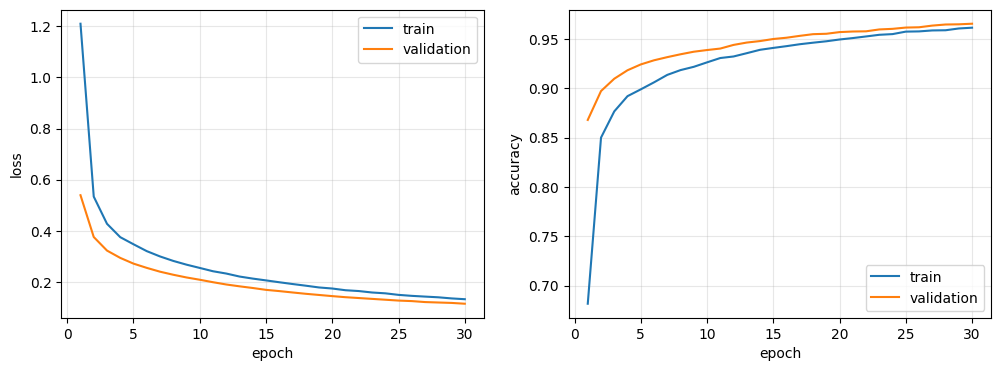

In [7]:
plot_history(history)

### Training time
- Bản Keras gốc (GPU trên Colab): 1.1312 phút cho 30 epoch, test accuracy 0.9648
- Bản PyTorch: xem kết quả ô trên (RTX 4060 Laptop)

# (4) Evaluate trained model

In [8]:
score = evaluate(model, test_loader, loss_fn)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss:

 0.11443541946262122
Test accuracy: 0.9656


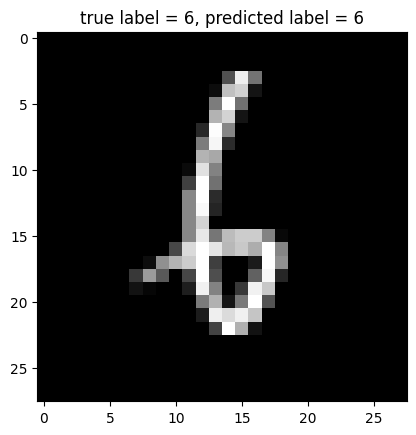

In [9]:
# select a test image randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]

# predict test image with trained model
pred_label = np.argmax(predict(model, np.expand_dims(test_img, axis=0)))

plt.imshow(test_img, cmap='gray')
plt.title('true label = %d, predicted label = %d' % (test_label, pred_label))
plt.show()

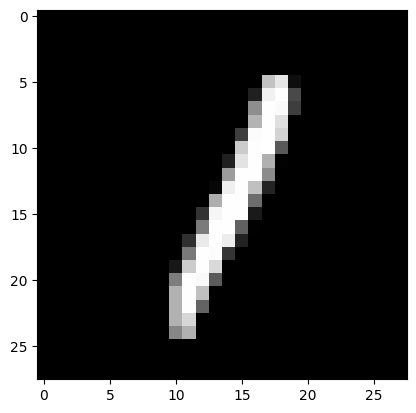

(np.int64(1), (28, 28))

In [10]:
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]
plt.imshow(test_img, cmap='gray')
plt.show()
test_label, test_img.shape

In [11]:
# Keras: model.input_shape, model.output_shape
with torch.no_grad():
    out = model(torch.zeros(1, 28, 28, device=device))
(None, 28, 28), (None,) + tuple(out.shape[1:])

((None, 28, 28), (None, 10))

In [12]:
y_pred = predict(model, np.expand_dims(test_img, axis=0))
print(y_pred.shape)
print(np.sum(y_pred, axis=1))      # tổng xác suất softmax = 1
print(np.argmax(y_pred, axis=1))

(1, 10)
[0.99999994]
[1]


### Lấy đặc trưng lớp `fc2`
Keras: `Model(inputs=model.input, outputs=[model.get_layer('fc2').output, model.output])`. PyTorch: gọi `model.features(x)` (đã viết sẵn trong lớp) và `model(x)`.

In [13]:
model.eval()
with torch.no_grad():
    xb = torch.as_tensor(np.expand_dims(test_img, axis=0), device=device)
    y_feat = model.features(xb).cpu().numpy()
    y_pred = torch.softmax(model(xb), dim=1).cpu().numpy()
print(y_feat.shape, y_pred.shape)
y_feat[0, :20]

(1, 512) (1, 10)


array([0.        , 0.4584095 , 0.26986083, 0.        , 0.        ,
       0.        , 0.14953476, 0.        , 0.61501104, 0.        ,
       0.        , 0.2917015 , 0.53793466, 0.6714233 , 0.0500707 ,
       0.        , 0.00517006, 0.        , 0.        , 0.47805995],
      dtype=float32)